# Customer Churn Prediction Using Machine Learning
**Final, reproducible notebook (canonical pipeline = "Experiment A", 46 features)**

This notebook is the *single source* of every result in the project. When you run it from top to bottom it:

1. loads the dataset and prepares the data,
2. trains and compares **Logistic Regression, Random Forest and XGBoost**,
3. checks the comparison with **cross-validation** (a single split can be lucky or unlucky),
4. explains the final model with **feature importance and SHAP**,
5. **saves** the model files (`models/`, XGBoost model in its native `.ubj` format), the result tables (`outputs/`) and the figures (`outputs/figures/`).

`train_model.py` runs the same pipeline from the command line (without figures); `tests/verify_models.py` checks that both give identical results.

The Streamlit app (`app.py`) uses exactly the files saved here, so notebook, CSV files and app always describe the same model.

**How to run:** select the project's virtual-environment kernel, then *Run All*. Run it from the `notebook/` folder (VS Code does this automatically).

## 1. Imports, folders and settings
`RANDOM_STATE = 42` makes every random choice repeatable. `TEST_SIZE = 0.20` keeps 20 % of customers aside for the final test.

In [1]:
import sys, json, platform, warnings, hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import shap
import sklearn, xgboost

from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold, cross_validate
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix,
                             classification_report, log_loss, brier_score_loss)
from xgboost import XGBClassifier

warnings.filterwarnings("ignore", category=FutureWarning)

# --- project folders (works whether the notebook is started in notebook/ or in the project root)
PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
DATA_FILE   = PROJECT_DIR / "data" / "Telco_customer_churn.xlsx"
MODELS_DIR  = PROJECT_DIR / "models"
OUTPUT_DIR  = PROJECT_DIR / "outputs"
FIG_DIR     = OUTPUT_DIR / "figures"
for folder in (MODELS_DIR, OUTPUT_DIR, FIG_DIR):
    folder.mkdir(parents=True, exist_ok=True)

# shared helper code (validation, preprocessing, risk bands) used by the app as well
sys.path.insert(0, str(PROJECT_DIR))
import churn_utils

RANDOM_STATE = 42
TEST_SIZE = 0.20
THRESHOLD = churn_utils.DECISION_THRESHOLD   # 0.50: we predict "churn" when the probability is above this value

def save_fig(name):
    """Save the current figure for the research paper (300 dpi) and show it."""
    plt.savefig(FIG_DIR / name, dpi=300, bbox_inches="tight")
    plt.show()

print("Project folder :", PROJECT_DIR)
print("Python", platform.python_version(), "| pandas", pd.__version__, "| numpy", np.__version__,
      "| scikit-learn", sklearn.__version__, "| xgboost", xgboost.__version__, "| shap", shap.__version__)

Project folder : /home/claude/final/Customer_Churn_Project
Python 3.12.3 | pandas 3.1.0 | numpy 2.5.4 | scikit-learn 1.9.1 | xgboost 3.4.1 | shap 0.54.1


/home/claude/venv_fresh/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Load the dataset
The file is the *Telco customer churn* sample data (IBM Cognos Analytics sample; a **fictional** telecom company in California). One row = one customer. The original file is never modified.

In [2]:
df = pd.read_excel(DATA_FILE)
print("Rows, columns:", df.shape)
assert df.shape == (7043, 33), "Unexpected dataset shape - is this the original file?"
df.head()

Rows, columns: (7043, 33)


,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,...,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,...,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,...,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,...,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,...,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices


## 3. Target variable: `Churn Label`
`Yes` = the customer left (churned), `No` = the customer stayed. Notice the **imbalance**: far fewer customers churn than stay. This is why accuracy alone is not enough later.

Churn Label
No     5174
Yes    1869
Name: count, dtype: int64
Churn Label
No     73.46
Yes    26.54
Name: proportion, dtype: float64


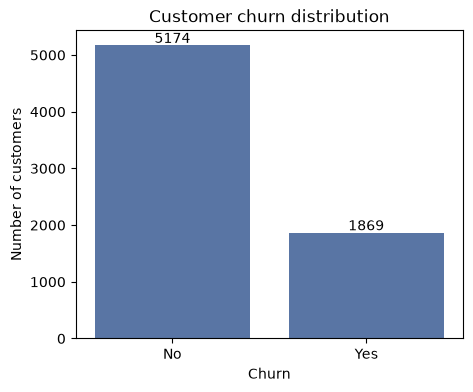

In [3]:
counts = df["Churn Label"].value_counts()
print(counts)
print((df["Churn Label"].value_counts(normalize=True) * 100).round(2))

plt.figure(figsize=(5, 4))
sns.countplot(data=df, x="Churn Label", order=["No", "Yes"], color="#4C72B0")
plt.title("Customer churn distribution")
plt.xlabel("Churn"); plt.ylabel("Number of customers")
for i, label in enumerate(["No", "Yes"]):
    plt.text(i, counts[label] + 40, f"{counts[label]}", ha="center")
save_fig("class_distribution.png")

## 4. Quick exploration (figures for the paper)
Two simple pictures: churn rate by contract type, and tenure for churned vs. stayed customers. These show *associations* in the data; they do not prove causes.

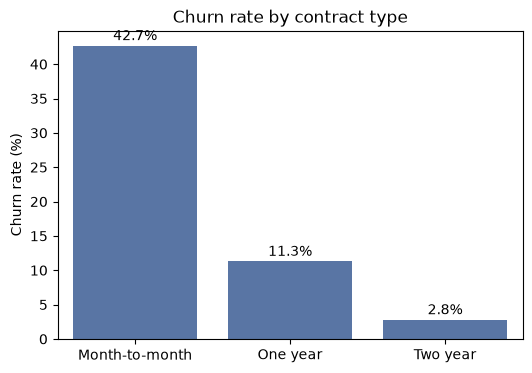

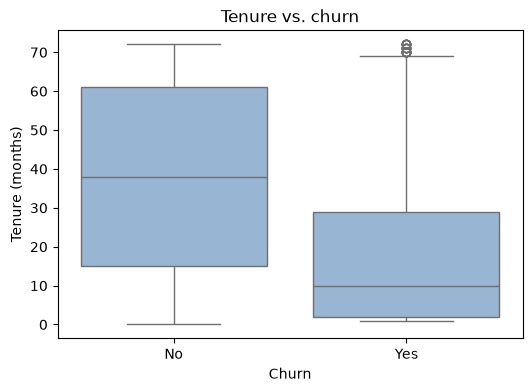

In [4]:
rate = (df.assign(churned=(df["Churn Label"] == "Yes"))
          .groupby("Contract")["churned"].mean().mul(100).round(1)
          .reindex(["Month-to-month", "One year", "Two year"]))
plt.figure(figsize=(6, 4))
ax = sns.barplot(x=rate.index, y=rate.values, color="#4C72B0")
for i, v in enumerate(rate.values):
    ax.text(i, v + 0.8, f"{v}%", ha="center")
plt.title("Churn rate by contract type"); plt.ylabel("Churn rate (%)"); plt.xlabel("")
save_fig("churn_rate_by_contract.png")

plt.figure(figsize=(6, 4))
sns.boxplot(data=df, x="Churn Label", y="Tenure Months", order=["No", "Yes"], color="#8FB4DE")
plt.title("Tenure vs. churn"); plt.xlabel("Churn"); plt.ylabel("Tenure (months)")
save_fig("tenure_vs_churn.png")

## 5. Choose the input features
We keep **19 customer attributes** (demographics, services, contract, billing) as inputs and exclude columns that would be wrong or useless:

| Excluded column(s) | Reason |
|---|---|
| `CustomerID`, `Count` | identifier / constant value, no predictive meaning |
| `Country`, `State` | constant (one country, one state) |
| `City`, `Zip Code`, `Lat Long`, `Latitude`, `Longitude` | very fine location detail (not used in this project) |
| `Churn Value` | the target written as 0/1 -> using it would be **cheating** (data leakage) |
| `Churn Score`, `CLTV` | scores computed by IBM *after the fact*; `Churn Score` is strongly tied to the outcome -> **leakage** |
| `Churn Reason` | only filled in for customers who already churned -> **leakage** |

In [5]:
FEATURE_COLUMNS = [
    "Gender", "Senior Citizen", "Partner", "Dependents", "Tenure Months", "Phone Service",
    "Multiple Lines", "Internet Service", "Online Security", "Online Backup", "Device Protection",
    "Tech Support", "Streaming TV", "Streaming Movies", "Contract", "Paperless Billing",
    "Payment Method", "Monthly Charges", "Total Charges",
]
model_df = df[FEATURE_COLUMNS + ["Churn Label"]].copy()
print("Model dataset shape:", model_df.shape)
print("Excluded:", [c for c in df.columns if c not in model_df.columns])

Model dataset shape: (7043, 20)
Excluded: ['CustomerID', 'Count', 'Country', 'State', 'City', 'Zip Code', 'Lat Long', 'Latitude', 'Longitude', 'Churn Value', 'Churn Score', 'CLTV', 'Churn Reason']


## 6. Missing values: `Total Charges`
`Total Charges` is stored as text and 11 values are blank. We convert to numbers and look at who those customers are.

**Change from the earlier notebook:** the earlier version filled these with the *median of the whole dataset* (computed before the train/test split, a small leak of test information). All 11 customers have **tenure = 0** (they have not been billed yet), so the logically correct value is **0**. This also needs no statistics from the data, so there is no leakage.

In [6]:
model_df["Total Charges"] = pd.to_numeric(model_df["Total Charges"], errors="coerce")
missing_mask = model_df["Total Charges"].isna()
print("Blank Total Charges:", int(missing_mask.sum()))
print("Tenure of those customers:", model_df.loc[missing_mask, "Tenure Months"].unique())
print("Their churn labels      :", model_df.loc[missing_mask, "Churn Label"].unique())

assert (model_df.loc[missing_mask, "Tenure Months"] == 0).all()   # safety check for the claim above
model_df["Total Charges"] = model_df["Total Charges"].fillna(0.0)
print("Remaining missing values:", int(model_df.isna().sum().sum()))

Blank Total Charges: 11
Tenure of those customers: [0]
Their churn labels      : <ArrowStringArray>
['No']
Length: 1, dtype: str
Remaining missing values: 0


## 7. Train / test split
We split **before** any learning from data:
* **Training set (80 %)**: the models learn from it.
* **Test set (20 %)**: kept hidden until the final evaluation, to measure performance on *unseen* customers.

`stratify=y` keeps the same churn percentage (~26.5 %) in both parts.

In [7]:
X = model_df.drop(columns="Churn Label")
y = (model_df["Churn Label"] == "Yes").astype(int)          # No = 0, Yes (churn) = 1

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y)

print("Train:", X_train.shape, "| churn rate %.4f" % y_train.mean())
print("Test :", X_test.shape,  "| churn rate %.4f" % y_test.mean())

NUMERICAL_COLUMNS   = ["Tenure Months", "Monthly Charges", "Total Charges"]
CATEGORICAL_COLUMNS = [c for c in X.columns if c not in NUMERICAL_COLUMNS]
assert len(CATEGORICAL_COLUMNS) == 16
print("\nNumerical  :", NUMERICAL_COLUMNS)
print("Categorical:", CATEGORICAL_COLUMNS)

Train: (5634, 19) | churn rate 0.2654
Test : (1409, 19) | churn rate 0.2654

Numerical  : ['Tenure Months', 'Monthly Charges', 'Total Charges']
Categorical: ['Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Online Security', 'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method']


## 8. Preprocessing (fitted on the training data only)
Models need numbers, so:
* **One-hot encoding** turns each category into 0/1 columns (e.g. `Contract_Two year`). `handle_unknown="ignore"` prevents a crash if an unseen category appears.
* **StandardScaler** rescales the 3 numeric columns (mean 0, standard deviation 1) so large numbers like `Total Charges` do not dominate.

Both are **fitted on the training set only** and then merely *applied* to the test set. Fitting on the test set would leak information.

The final matrix is `[3 scaled numeric columns | 43 one-hot columns] = 46 features`. This exact order is reused by the app.

In [8]:
encoder = OneHotEncoder(handle_unknown="ignore", drop=None, sparse_output=False)
scaler  = StandardScaler()

X_train_cat = encoder.fit_transform(X_train[CATEGORICAL_COLUMNS])
X_test_cat  = encoder.transform(X_test[CATEGORICAL_COLUMNS])
X_train_num = scaler.fit_transform(X_train[NUMERICAL_COLUMNS])
X_test_num  = scaler.transform(X_test[NUMERICAL_COLUMNS])

X_train_processed = np.hstack([X_train_num, X_train_cat])
X_test_processed  = np.hstack([X_test_num,  X_test_cat])

feature_names = NUMERICAL_COLUMNS + list(encoder.get_feature_names_out(CATEGORICAL_COLUMNS))
assert X_train_processed.shape[1] == len(feature_names) == 46
print("Processed training shape:", X_train_processed.shape)
print("Processed test shape    :", X_test_processed.shape)
print("First 6 feature names   :", feature_names[:6])

Processed training shape: (5634, 46)
Processed test shape    : (1409, 46)
First 6 feature names   : ['Tenure Months', 'Monthly Charges', 'Total Charges', 'Gender_Female', 'Gender_Male', 'Senior Citizen_No']


## 9. Train the three models
* **Logistic Regression**: a simple model that combines features with weights into a probability.
* **Random Forest**: many decision trees voting together.
* **XGBoost**: trees built one after another, each correcting the previous trees' mistakes.

Settings are unchanged from the original project. (`n_jobs=1` for XGBoost only makes results identical from computer to computer.)

In [9]:
lr_model = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
rf_model = RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE)
xgb_model = XGBClassifier(n_estimators=200, max_depth=4, learning_rate=0.05,
                          subsample=0.8, colsample_bytree=0.8,
                          random_state=RANDOM_STATE, eval_metric="logloss", n_jobs=1)

models = {"Logistic Regression": lr_model, "Random Forest": rf_model, "XGBoost": xgb_model}
for name, m in models.items():
    m.fit(X_train_processed, y_train)
    print(f"{name} trained")

# predicted churn probability of every test customer, for each model
probs = {name: m.predict_proba(X_test_processed)[:, 1] for name, m in models.items()}
# class decision: churn if probability > THRESHOLD (same rule the app uses; also the library's own tie rule)
preds = {name: (p > THRESHOLD).astype(int) for name, p in probs.items()}
for name, m in models.items():                       # safety check: identical to the library's own predict()
    assert (preds[name] == m.predict(X_test_processed)).all()

Logistic Regression trained


Random Forest trained
XGBoost trained


## 10. Evaluate on the unseen test set
Terms (churn = the "positive" class):
* **Accuracy**: share of all customers classified correctly. Misleading here: predicting "stays" for everyone would already score ~73 %.
* **Precision**: of customers we *flag* as churners, how many really churn?
* **Recall**: of customers who *really churn*, how many do we catch? (Key for retention work.)
* **F1-score**: one number balancing precision and recall.
* **ROC-AUC**: how well the model *ranks* churners above non-churners (0.5 = guessing, 1.0 = perfect), independent of any threshold.

In [10]:
def evaluate(name, y_true, prob, pred):
    return {"Model": name,
            "Accuracy":  accuracy_score(y_true, pred),
            "Precision": precision_score(y_true, pred),
            "Recall":    recall_score(y_true, pred),
            "F1 Score":  f1_score(y_true, pred),
            "ROC-AUC":   roc_auc_score(y_true, prob)}

model_comparison = pd.DataFrame([evaluate(n, y_test, probs[n], preds[n]) for n in models])
model_comparison.to_csv(OUTPUT_DIR / "model_comparison.csv", index=False)
model_comparison.round(4)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.8020,0.6435,0.5695,0.6043,0.8489
1,Random Forest,0.7949,0.6412,0.5160,0.5719,0.8330
2,XGBoost,0.8133,0.6773,0.5668,0.6172,0.8584


In [11]:
# Detailed per-class report for every model (also saved as text for the paper)
report_text = ""
for name in models:
    report_text += f"=== {name} ===\n"
    report_text += classification_report(y_test, preds[name], target_names=["No Churn", "Churn"], digits=4)
    report_text += "\n"
(OUTPUT_DIR / "classification_reports.txt").write_text(report_text, encoding="utf-8")
print(report_text)

=== Logistic Regression ===
              precision    recall  f1-score   support

    No Churn     0.8506    0.8860    0.8680      1035
       Churn     0.6435    0.5695    0.6043       374

    accuracy                         0.8020      1409
   macro avg     0.7471    0.7278    0.7361      1409
weighted avg     0.7957    0.8020    0.7980      1409

=== Random Forest ===
              precision    recall  f1-score   support

    No Churn     0.8366    0.8957    0.8651      1035
       Churn     0.6412    0.5160    0.5719       374

    accuracy                         0.7949      1409
   macro avg     0.7389    0.7058    0.7185      1409
weighted avg     0.7848    0.7949    0.7873      1409

=== XGBoost ===
              precision    recall  f1-score   support

    No Churn     0.8522    0.9024    0.8766      1035
       Churn     0.6773    0.5668    0.6172       374

    accuracy                         0.8133      1409
   macro avg     0.7648    0.7346    0.7469      1409
weighted

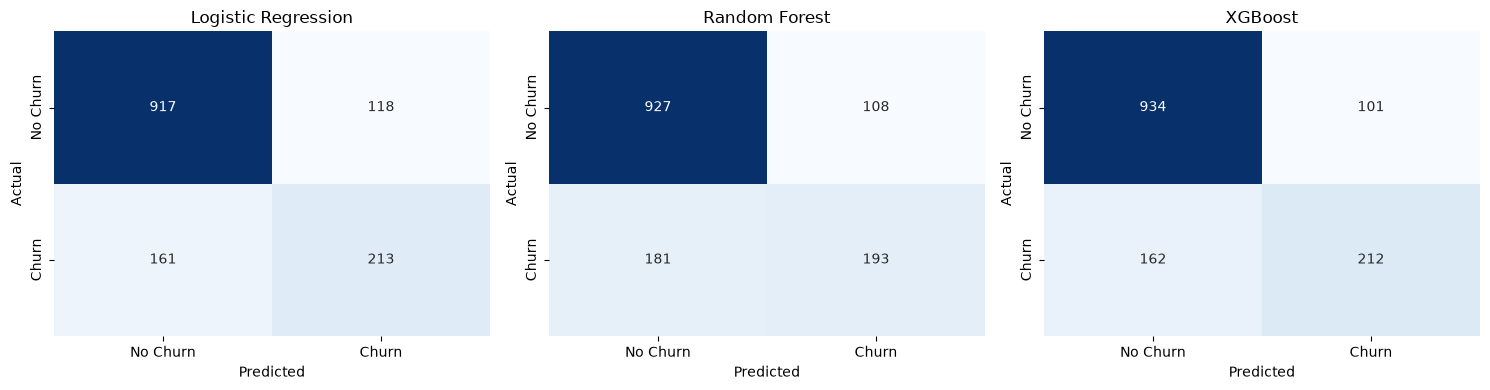

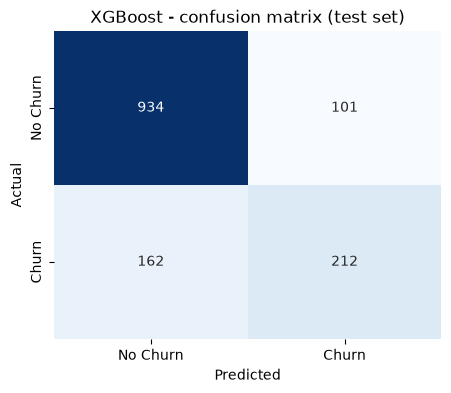

XGBoost: [[TN, FP], [FN, TP]] = [[934, 101], [162, 212]]


In [12]:
# Confusion matrices: rows = actual, columns = predicted
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
confusions = {}
for ax, name in zip(axes, models):
    cm = confusion_matrix(y_test, preds[name]); confusions[name] = cm
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["No Churn", "Churn"], yticklabels=["No Churn", "Churn"])
    ax.set_title(name); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout()
save_fig("confusion_matrices_all_models.png")

plt.figure(figsize=(5, 4))
sns.heatmap(confusions["XGBoost"], annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["No Churn", "Churn"], yticklabels=["No Churn", "Churn"])
plt.title("XGBoost - confusion matrix (test set)"); plt.xlabel("Predicted"); plt.ylabel("Actual")
save_fig("confusion_matrix_xgboost.png")
print("XGBoost: [[TN, FP], [FN, TP]] =", confusions["XGBoost"].tolist())

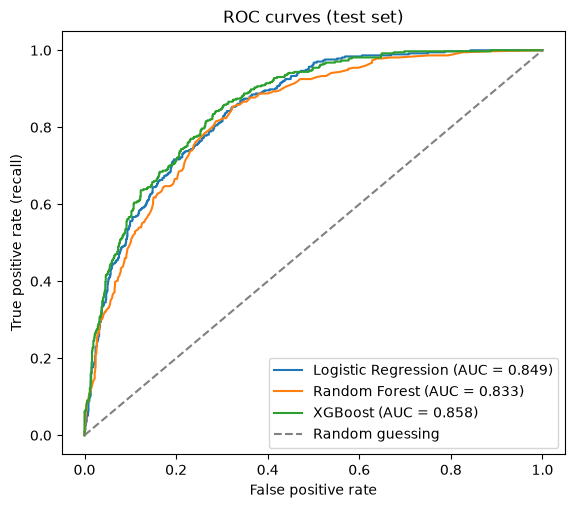

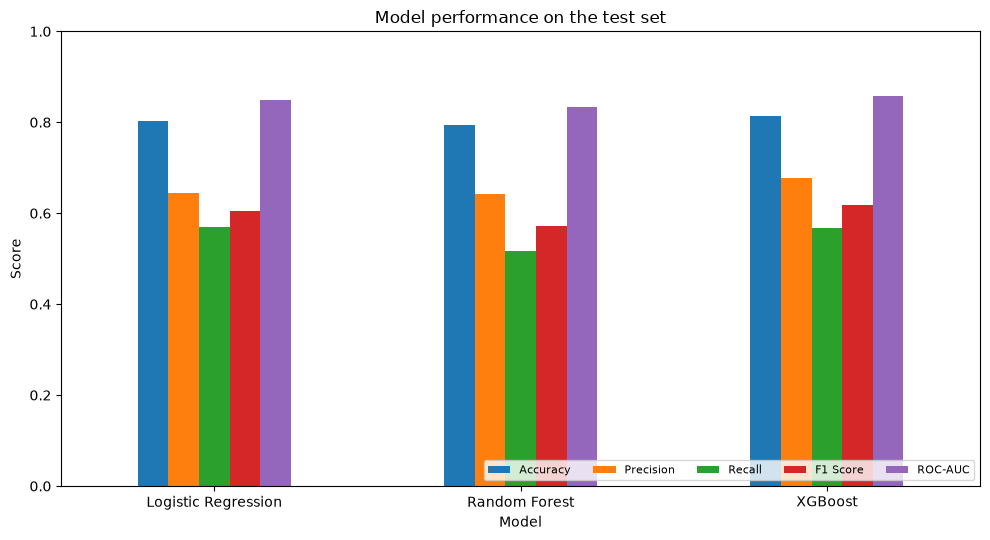

In [13]:
# ROC curves
plt.figure(figsize=(6.5, 5.5))
for name in models:
    fpr, tpr, _ = roc_curve(y_test, probs[name])
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, probs[name]):.3f})")
plt.plot([0, 1], [0, 1], "--", color="grey", label="Random guessing")
plt.xlabel("False positive rate"); plt.ylabel("True positive rate (recall)")
plt.title("ROC curves (test set)"); plt.legend(loc="lower right")
save_fig("roc_curves.png")

# Model comparison bar chart
model_comparison.set_index("Model").plot(kind="bar", figsize=(10, 5.5), rot=0)
plt.ylim(0, 1); plt.ylabel("Score"); plt.title("Model performance on the test set")
plt.legend(loc="lower right", ncol=5, fontsize=8)
plt.tight_layout()
save_fig("model_comparison.png")

## 11. Is the comparison trustworthy? Repeated cross-validation
The table above comes from **one** split of **1,409** customers. A different split could change the ranking, especially when scores are close. Cross-validation repeats the experiment on many splits (here **5 folds x 3 repeats = 15 runs**) and reports the *average and spread*.

Here the scaler and encoder live **inside** each pipeline, so they are re-fitted on each fold's training part only (no leakage). We also record **log-loss** and **Brier score** (lower = better), which measure how good the predicted *probabilities* are, because the app shows probabilities.

In [14]:
def make_pipeline(model):
    prep = ColumnTransformer([("num", StandardScaler(), NUMERICAL_COLUMNS),
                              ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL_COLUMNS)])
    return Pipeline([("prep", prep), ("model", model)])

cv_models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),
    "XGBoost": XGBClassifier(n_estimators=200, max_depth=4, learning_rate=0.05, subsample=0.8,
                             colsample_bytree=0.8, random_state=RANDOM_STATE, eval_metric="logloss", n_jobs=1),
}
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)   # same folds for every model
scoring = {"accuracy": "accuracy", "precision": "precision", "recall": "recall", "f1": "f1",
           "roc_auc": "roc_auc", "neg_log_loss": "neg_log_loss", "neg_brier": "neg_brier_score"}

cv_raw = {}
for name, m in cv_models.items():
    cv_raw[name] = cross_validate(make_pipeline(m), X, y, cv=cv, scoring=scoring)
    print(name, "done")

rows = []
for name, r in cv_raw.items():
    row = {"Model": name}
    for key in ["accuracy", "precision", "recall", "f1", "roc_auc"]:
        row[f"{key}_mean"] = r[f"test_{key}"].mean(); row[f"{key}_std"] = r[f"test_{key}"].std()
    row["log_loss_mean"] = -r["test_neg_log_loss"].mean(); row["log_loss_std"] = r["test_neg_log_loss"].std()
    row["brier_mean"] = -r["test_neg_brier"].mean();       row["brier_std"] = r["test_neg_brier"].std()
    rows.append(row)
cv_results = pd.DataFrame(rows)
cv_results.to_csv(OUTPUT_DIR / "cross_validation_results.csv", index=False)

# readable "mean +/- std" view
view = pd.DataFrame({"Model": cv_results["Model"]})
for key in ["accuracy", "precision", "recall", "f1", "roc_auc", "log_loss", "brier"]:
    view[key] = [f"{m:.4f} +/- {s:.4f}" for m, s in zip(cv_results[f"{key}_mean"], cv_results[f"{key}_std"])]
view

Logistic Regression done


Random Forest done


XGBoost done


,Model,accuracy,precision,recall,f1,roc_auc,log_loss,brier
0,Logistic Regression,0.8105 +/- 0.0064,0.6642 +/- 0.0179,0.5800 +/- 0.0155,0.6190 +/- 0.0116,0.8573 +/- 0.0066,0.4032 +/- 0.0080,0.1310 +/- 0.0027
1,Random Forest,0.7956 +/- 0.0078,0.6458 +/- 0.0173,0.5092 +/- 0.0333,0.5688 +/- 0.0237,0.8362 +/- 0.0067,0.4623 +/- 0.0228,0.1408 +/- 0.0032
2,XGBoost,0.8068 +/- 0.0066,0.6629 +/- 0.0179,0.5541 +/- 0.0162,0.6034 +/- 0.0126,0.8617 +/- 0.0063,0.3962 +/- 0.0081,0.1295 +/- 0.0029


In [15]:
# Paired comparison on the SAME 15 folds: XGBoost minus Logistic Regression
paired_rows = []
# (scikit-learn stores log-loss as a NEGATIVE number, so "higher is better" holds for all four rows below)
for key, label in [("roc_auc", "ROC-AUC gain"), ("f1", "F1 gain"),
                   ("recall", "Recall gain"), ("neg_log_loss", "Log-loss reduction (lower loss = better)")]:
    diff = cv_raw["XGBoost"][f"test_{key}"] - cv_raw["Logistic Regression"][f"test_{key}"]
    paired_rows.append({"Metric": label, "Mean difference (XGB - LR)": diff.mean(),
                        "Std of difference": diff.std(), "Folds where XGBoost is better (of 15)": int((diff > 0).sum())})
paired = pd.DataFrame(paired_rows)
paired.to_csv(OUTPUT_DIR / "xgboost_vs_logistic_paired_cv.csv", index=False)
print("Differences are shown so that a POSITIVE number always means 'XGBoost better'.")
print("Folds overlap, so treat these as descriptive evidence, not a formal significance test.\n")
paired.round(4)

Differences are shown so that a POSITIVE number always means 'XGBoost better'.
Folds overlap, so treat these as descriptive evidence, not a formal significance test.



,Metric,Mean difference (XGB - LR),Std of difference,Folds where XGBoost is better (of 15)
0,ROC-AUC gain,0.0044,0.0045,13
1,F1 gain,-0.0156,0.0096,2
2,Recall gain,-0.0259,0.0158,0
3,Log-loss reduction (lower loss = better),0.0070,0.0056,14


## 12. Model selection evidence (computed, not typed by hand)
The tables below simply report which model is best on each measure, on the single test split and in cross-validation. **Read them before claiming that a model is "best".**

In [16]:
higher_better = ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"]
test_best = {m: model_comparison.loc[model_comparison[m].idxmax(), "Model"] for m in higher_better}

cv_map = {"Accuracy": "accuracy_mean", "Precision": "precision_mean", "Recall": "recall_mean",
          "F1 Score": "f1_mean", "ROC-AUC": "roc_auc_mean"}
cv_best = {m: cv_results.loc[cv_results[c].idxmax(), "Model"] for m, c in cv_map.items()}
cv_best["Log-loss (lower better)"]   = cv_results.loc[cv_results["log_loss_mean"].idxmin(), "Model"]
cv_best["Brier score (lower better)"] = cv_results.loc[cv_results["brier_mean"].idxmin(), "Model"]
test_best["Log-loss (lower better)"] = "-"
test_best["Brier score (lower better)"] = "-"

selection = pd.DataFrame({"Best on single test split": pd.Series(test_best),
                          "Best in 15-run cross-validation": pd.Series(cv_best)})
selection.index.name = "Measure"
selection.to_csv(OUTPUT_DIR / "model_selection_evidence.csv")
selection

,Best on single test split,Best in 15-run cross-validation
Measure,,
Accuracy,XGBoost,Logistic Regression
Precision,XGBoost,Logistic Regression
Recall,Logistic Regression,Logistic Regression
F1 Score,XGBoost,Logistic Regression
ROC-AUC,XGBoost,XGBoost
Log-loss (lower better),-,XGBoost
Brier score (lower better),-,XGBoost


### Final model used by the app
The project's design (and the original report) deploys **XGBoost**. We keep it, because it gives the highest ROC-AUC (ranking quality, the property the app's probability/risk display depends on) *if the table above confirms it*. The same table also shows where another model is as good or better. That is reported honestly in the README and must be mentioned in the paper: the three models perform **very similarly**.

In [17]:
FINAL_MODEL_NAME = "XGBoost"
final_model = models[FINAL_MODEL_NAME]
final_probs = probs[FINAL_MODEL_NAME]
print("Final model:", FINAL_MODEL_NAME)

Final model: XGBoost


## 13. Threshold and risk-band analysis (final model)
The model outputs a probability; we turn it into a decision using a **threshold**. The default **0.50** is what all metrics above use. A *lower* threshold catches more churners (higher recall) but flags more customers who would have stayed (lower precision). The table makes that trade-off visible. It is **informational**; the project keeps 0.50.

In [18]:
rows = []
for t in [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]:
    p = (final_probs > t).astype(int)
    rows.append({"Threshold": t, "Customers flagged": int(p.sum()), "Precision": precision_score(y_test, p),
                 "Recall": recall_score(y_test, p), "F1 Score": f1_score(y_test, p)})
threshold_table = pd.DataFrame(rows)
threshold_table.to_csv(OUTPUT_DIR / "threshold_analysis.csv", index=False)
threshold_table.round(4)

,Threshold,Customers flagged,Precision,Recall,F1 Score
0,0.20,655,0.4947,0.8663,0.6297
1,0.25,596,0.5151,0.8209,0.6330
2,0.30,527,0.5446,0.7674,0.6371
3,0.35,472,0.5636,0.7112,0.6288
4,0.40,432,0.5926,0.6845,0.6352
5,0.45,368,0.6467,0.6364,0.6415
6,0.50,313,0.6773,0.5668,0.6172
7,0.55,250,0.7040,0.4706,0.5641
8,0.60,214,0.7430,0.4251,0.5408


**Risk bands used in the app** (fixed in advance in `churn_utils.py`, *not* tuned on the test set): Low < 0.30, Medium 0.30 to 0.50, High > 0.50. "High risk" is exactly "predicted to churn". The check below shows the **actual** churn rate of test customers in each band; for the bands to be meaningful it should rise from Low to High.

In [19]:
bands = pd.Series([churn_utils.risk_category(p) for p in final_probs], index=y_test.index, name="Risk band")
risk_check = (pd.DataFrame({"Risk band": bands, "churned": y_test})
                .groupby("Risk band")["churned"].agg(Customers="count", Actual_churners="sum", Actual_churn_rate="mean")
                .reindex(["Low Risk", "Medium Risk", "High Risk"]))
risk_check.to_csv(OUTPUT_DIR / "risk_band_check.csv")
risk_check.round(4)

,Customers,Actual_churners,Actual_churn_rate
Risk band,,,
Low Risk,882,87,0.0986
Medium Risk,214,75,0.3505
High Risk,313,212,0.6773


**How much can we trust one test-set number?** A test set of 1,409 customers is a *sample*. We re-draw 1,000 random samples (with replacement) from the test predictions (**bootstrap**) and report the range that covers the middle 95 % of the results. A wide range means the exact value is uncertain.

In [20]:
rng = np.random.default_rng(RANDOM_STATE)
y_arr = y_test.to_numpy()
boot = {"Accuracy": [], "Precision": [], "Recall": [], "F1 Score": [], "ROC-AUC": []}
for _ in range(1000):
    idx = rng.integers(0, len(y_arr), len(y_arr))
    yb, pb = y_arr[idx], final_probs[idx]
    cb = (pb > THRESHOLD).astype(int)
    boot["Accuracy"].append(accuracy_score(yb, cb));  boot["Precision"].append(precision_score(yb, cb))
    boot["Recall"].append(recall_score(yb, cb));      boot["F1 Score"].append(f1_score(yb, cb))
    boot["ROC-AUC"].append(roc_auc_score(yb, pb))
ci_table = pd.DataFrame({"Metric": list(boot),
                         "Test-set value": [float(model_comparison.loc[model_comparison["Model"] == FINAL_MODEL_NAME, m].iloc[0]) for m in boot],
                         "95% CI lower": [np.percentile(v, 2.5) for v in boot.values()],
                         "95% CI upper": [np.percentile(v, 97.5) for v in boot.values()]})
ci_table.to_csv(OUTPUT_DIR / "test_metric_confidence_intervals.csv", index=False)
ci_table.round(4)

,Metric,Test-set value,95% CI lower,95% CI upper
0,Accuracy,0.8133,0.7935,0.8339
1,Precision,0.6773,0.6229,0.7252
2,Recall,0.5668,0.5154,0.6175
3,F1 Score,0.6172,0.5727,0.6581
4,ROC-AUC,0.8584,0.8371,0.8773


## 14. Feature importance (what the model relies on)
XGBoost's built-in importance (here *gain*, normalised to sum to 1) says how much each input helped the model reduce its errors. **It is not causation**: it tells us what the model *uses*, not what *causes* customers to leave. Because we one-hot encode, related columns (e.g. `Online Security_No` and `Online Security_Yes`) share the credit.

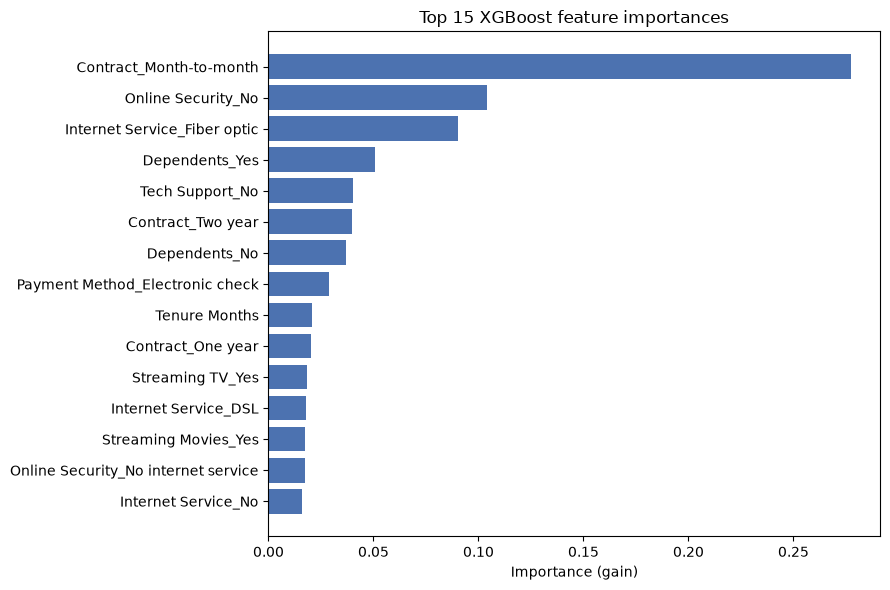

,Feature,Importance
0,Contract_Month-to-month,0.2773
1,Online Security_No,0.1042
2,Internet Service_Fiber optic,0.0902
3,Dependents_Yes,0.0505
4,Tech Support_No,0.0403
5,Contract_Two year,0.0398
6,Dependents_No,0.0369
7,Payment Method_Electronic check,0.0289
8,Tenure Months,0.0209
9,Contract_One year,0.0204


In [21]:
feature_importance = (pd.DataFrame({"Feature": feature_names, "Importance": final_model.feature_importances_})
                        .sort_values("Importance", ascending=False).reset_index(drop=True))
feature_importance.to_csv(OUTPUT_DIR / "xgboost_feature_importance.csv", index=False)

top = feature_importance.head(15)
plt.figure(figsize=(9, 6))
plt.barh(top["Feature"][::-1], top["Importance"][::-1], color="#4C72B0")
plt.xlabel("Importance (gain)"); plt.title("Top 15 XGBoost feature importances")
plt.tight_layout()
save_fig("feature_importance_top15.png")
feature_importance.head(15).round(4)

## 15. SHAP explanations
**SHAP** assigns every feature a contribution (in log-odds units) to *each individual* prediction: positive pushes toward churn, negative toward staying. Averaging absolute SHAP values over many customers gives a global ranking. Again this explains **the model**, not real-world causes.

In the dot plot each dot is one test customer; colour = feature value (red high, blue low); position left/right = pushes toward stay/churn. (Colours here refer to the *scaled* value for numeric columns.)

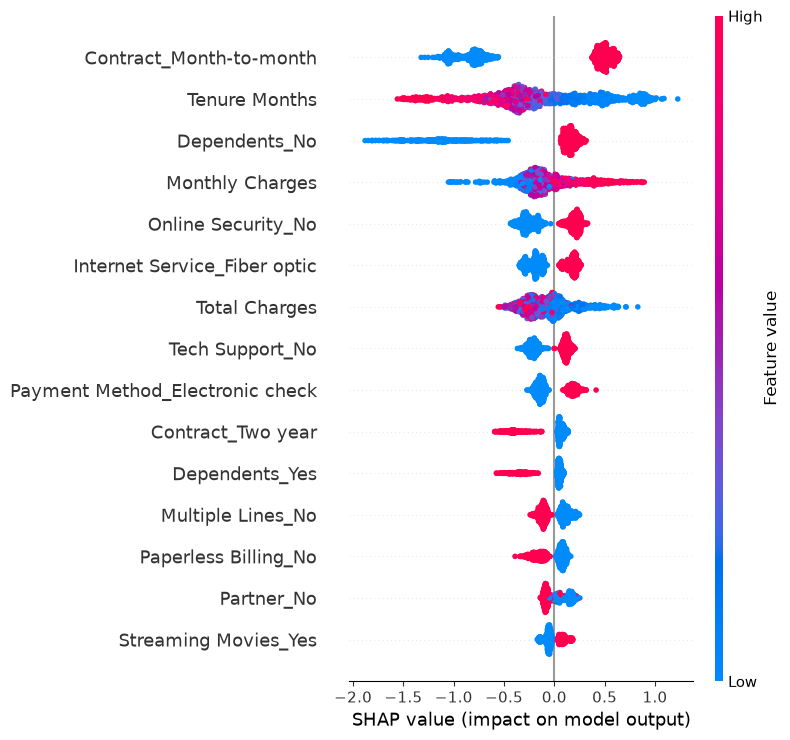

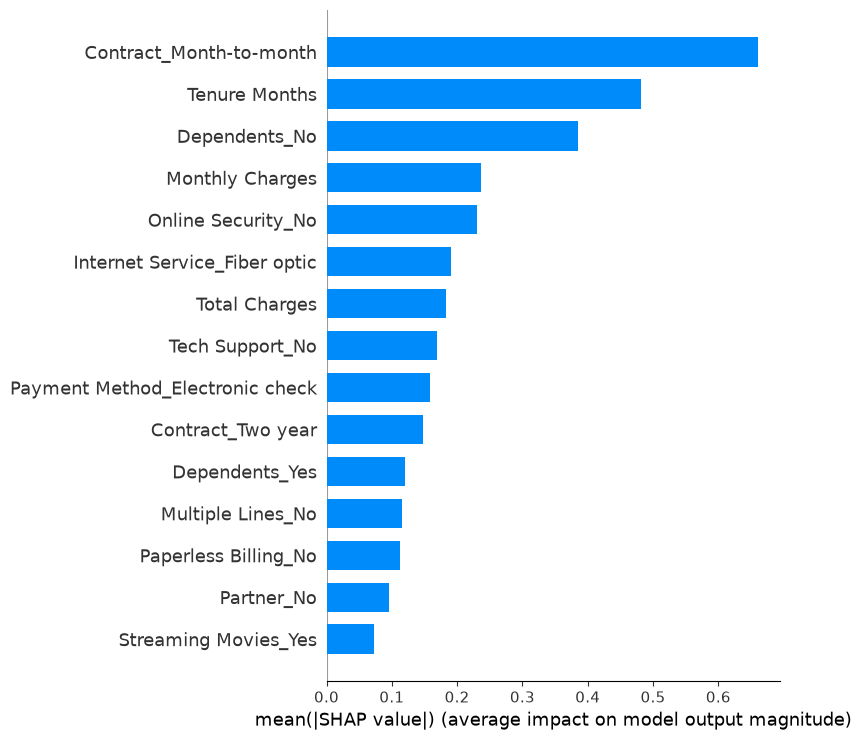

,Feature,Mean_abs_SHAP
0,Contract_Month-to-month,0.6613
1,Tenure Months,0.4812
2,Dependents_No,0.3857
3,Monthly Charges,0.2371
4,Online Security_No,0.2299
5,Internet Service_Fiber optic,0.1911
6,Total Charges,0.1823
7,Tech Support_No,0.1687
8,Payment Method_Electronic check,0.1591
9,Contract_Two year,0.1474


In [22]:
explainer = shap.TreeExplainer(final_model)
shap_values = explainer.shap_values(X_test_processed)
assert shap_values.shape == X_test_processed.shape == (len(X_test), len(feature_names))

plt.figure()
shap.summary_plot(shap_values, X_test_processed, feature_names=feature_names, max_display=15, show=False)
plt.tight_layout()
save_fig("shap_summary_beeswarm.png")

plt.figure()
shap.summary_plot(shap_values, X_test_processed, feature_names=feature_names, plot_type="bar",
                  max_display=15, show=False)
plt.tight_layout()
save_fig("shap_summary_bar.png")

shap_importance = (pd.DataFrame({"Feature": feature_names, "Mean_abs_SHAP": np.abs(shap_values).mean(axis=0)})
                     .sort_values("Mean_abs_SHAP", ascending=False).reset_index(drop=True))
shap_importance.to_csv(OUTPUT_DIR / "shap_mean_abs_importance.csv", index=False)
shap_importance.head(10).round(4)

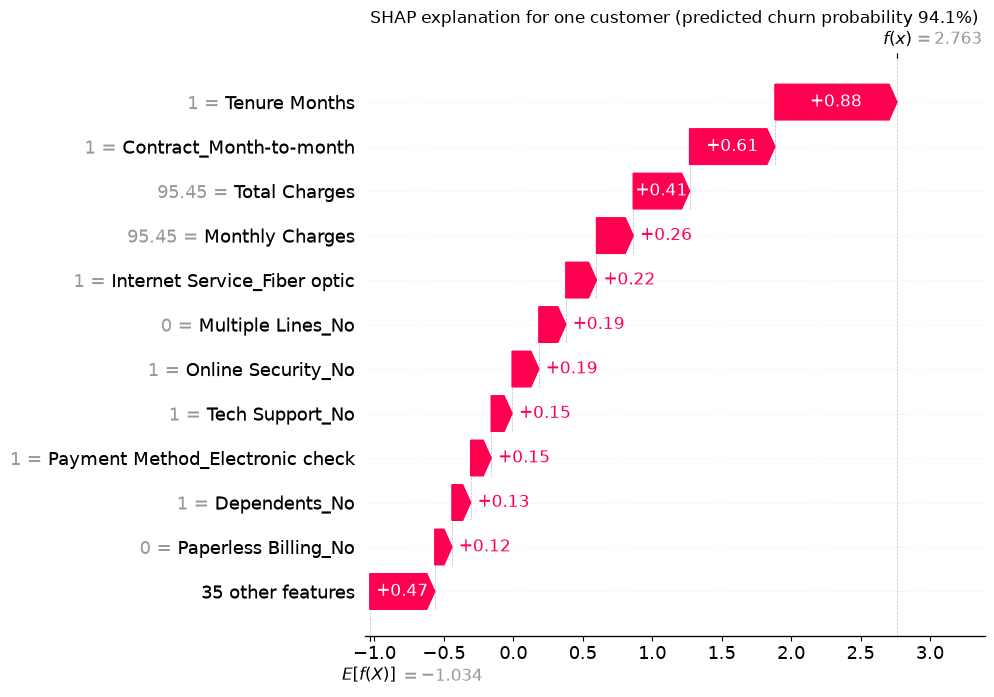

Actual outcome of this customer: Churn


In [23]:
# Explain ONE customer: the test customer with the highest predicted churn probability
i = int(np.argmax(final_probs))
display_values = np.hstack([X_test[NUMERICAL_COLUMNS].values, X_test_cat])   # original (unscaled) numbers for readable labels
base_value = float(np.ravel(explainer.expected_value)[0])
explanation = shap.Explanation(values=shap_values[i], base_values=base_value,
                               data=display_values[i], feature_names=feature_names)
plt.figure()
shap.plots.waterfall(explanation, max_display=12, show=False)
plt.title(f"SHAP explanation for one customer (predicted churn probability {final_probs[i]:.1%})")
save_fig("shap_waterfall_example.png")
print("Actual outcome of this customer:", "Churn" if y_test.iloc[i] == 1 else "No churn")

## 16. Save everything the app needs
The files are saved **together** so they always match:

| File | What it is |
|---|---|
| `final_xgboost_churn_model.ubj` | the XGBoost model in XGBoost's **own native format** (more robust than a Python pickle) |
| `final_churn_encoder.pkl`, `final_churn_scaler.pkl` | the fitted one-hot encoder and scaler |
| `numerical_columns.json`, `categorical_columns.json` | the exact column lists (and their order) |
| `model_metadata.json` | feature names, thresholds, valid input ranges, library versions, test metrics |
| `manifest.json` | SHA-256 checksums of the binary files, so a damaged copy is detected instead of giving wrong predictions |

`outputs/test_predictions.csv` stores every test customer's true outcome and predicted probabilities, so the app can draw the ROC curve and confusion matrices from real results.

In [24]:
final_model.save_model(str(MODELS_DIR / churn_utils.MODEL_FILE))      # native XGBoost format
joblib.dump(encoder, MODELS_DIR / churn_utils.ENCODER_FILE)
joblib.dump(scaler,  MODELS_DIR / churn_utils.SCALER_FILE)
(MODELS_DIR / churn_utils.NUMERICAL_FILE).write_text(json.dumps(NUMERICAL_COLUMNS, indent=2), encoding="utf-8")
(MODELS_DIR / churn_utils.CATEGORICAL_FILE).write_text(json.dumps(CATEGORICAL_COLUMNS, indent=2), encoding="utf-8")

def to_py(v):
    return int(v) if float(v).is_integer() else float(v)

metadata = {
    "pipeline": "Experiment A (canonical): StandardScaler + one-hot (drop=None), 46 features, blank Total Charges set to 0",
    "final_model": FINAL_MODEL_NAME,
    "model_format": "xgboost-ubj (native XGBoost format)",
    "model_file": churn_utils.MODEL_FILE,
    "random_state": RANDOM_STATE, "test_size": TEST_SIZE,
    "n_train": int(len(X_train)), "n_test": int(len(X_test)),
    "decision_threshold": churn_utils.DECISION_THRESHOLD,
    "low_risk_upper": churn_utils.LOW_RISK_UPPER,
    "numerical_columns": NUMERICAL_COLUMNS,
    "categorical_columns": CATEGORICAL_COLUMNS,
    "feature_names": feature_names,
    # valid-input limits for the app: min/max over the WHOLE dataset (a plausibility check on user input, not learned by the model)
    "numeric_ranges": {c: [to_py(X[c].min()), to_py(X[c].max())] for c in NUMERICAL_COLUMNS},
    "dataset": {"file": "data/Telco_customer_churn.xlsx", "rows": int(len(df)),
                "md5": hashlib.md5(DATA_FILE.read_bytes()).hexdigest()},
    "test_metrics": {k: float(v) for k, v in
                     model_comparison[model_comparison["Model"] == FINAL_MODEL_NAME].iloc[0].drop("Model").items()},
    "library_versions": {"python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__,
                         "scikit-learn": sklearn.__version__, "xgboost": xgboost.__version__, "shap": shap.__version__},
}
(MODELS_DIR / churn_utils.METADATA_FILE).write_text(json.dumps(metadata, indent=2), encoding="utf-8")
churn_utils.write_manifest(str(MODELS_DIR))

pd.DataFrame({"row_index": X_test.index, "actual": y_test.to_numpy(),
              "prob_logistic_regression": probs["Logistic Regression"],
              "prob_random_forest": probs["Random Forest"],
              "prob_xgboost": probs["XGBoost"]}).to_csv(OUTPUT_DIR / "test_predictions.csv", index=False)
print("Saved:", sorted(p.name for p in MODELS_DIR.iterdir()))

Saved: ['categorical_columns.json', 'final_churn_encoder.pkl', 'final_churn_scaler.pkl', 'final_xgboost_churn_model.ubj', 'manifest.json', 'model_metadata.json', 'numerical_columns.json']


## 17. Self-check: does the app's code path reproduce the notebook?
We reload the saved files exactly the way the app does (this also verifies the checksums), run the **whole test set** through `churn_utils`, and require identical numbers. We also try one valid and one impossible customer.

In [25]:
art = churn_utils.load_artifacts(MODELS_DIR)

X_check = churn_utils.build_model_input(X_test, art)
assert np.allclose(X_check, X_test_processed), "App preprocessing differs from training preprocessing!"
p_check = art["model"].predict_proba(X_check)[:, 1]
assert np.allclose(p_check, final_probs), "Reloaded model gives different probabilities!"
print("OK: saved files + churn_utils reproduce the notebook's test-set probabilities exactly.")

sample = {"Gender": "Female", "Senior Citizen": "No", "Partner": "No", "Dependents": "No", "Tenure Months": 5,
          "Phone Service": "Yes", "Multiple Lines": "No", "Internet Service": "Fiber optic",
          "Online Security": "No", "Online Backup": "No", "Device Protection": "No", "Tech Support": "No",
          "Streaming TV": "Yes", "Streaming Movies": "Yes", "Contract": "Month-to-month",
          "Paperless Billing": "Yes", "Payment Method": "Electronic check",
          "Monthly Charges": 85.50, "Total Charges": 427.50}
ranges = art["metadata"]["numeric_ranges"]
print("\nValid customer  -> errors:", churn_utils.validate_customer(sample, ranges))
print("Prediction      ->", churn_utils.predict_customer(sample, art))

bad = dict(sample, **{"Internet Service": "No", "Online Security": "Yes"})
print("\nImpossible customer -> errors:")
for e in churn_utils.validate_customer(bad, ranges): print("  -", e)

OK: saved files + churn_utils reproduce the notebook's test-set probabilities exactly.

Valid customer  -> errors: []
Prediction      -> {'probability': 0.7474034428596497, 'predicted_churn': True, 'label': 'Likely to Churn', 'risk': 'High Risk', 'message': 'Likely to Churn'}

Impossible customer -> errors:
  - Internet Service is 'No', so Online Security must be 'No internet service'.
  - Internet Service is 'No', so Online Backup must be 'No internet service'.
  - Internet Service is 'No', so Device Protection must be 'No internet service'.
  - Internet Service is 'No', so Tech Support must be 'No internet service'.
  - Internet Service is 'No', so Streaming TV must be 'No internet service'.
  - Internet Service is 'No', so Streaming Movies must be 'No internet service'.


In [26]:
print("=" * 64)
print("FINAL RESULTS  (", FINAL_MODEL_NAME, ", test set of", len(X_test), "customers )")
print("=" * 64)
for k, v in metadata["test_metrics"].items():
    print(f"{k:10s}: {v:.4f}")
print("\nFiles written to:", MODELS_DIR, "and", OUTPUT_DIR)
print("Figures:", sorted(p.name for p in FIG_DIR.iterdir()))

FINAL RESULTS  ( XGBoost , test set of 1409 customers )
Accuracy  : 0.8133
Precision : 0.6773
Recall    : 0.5668
F1 Score  : 0.6172
ROC-AUC   : 0.8584

Files written to: /home/claude/final/Customer_Churn_Project/models and /home/claude/final/Customer_Churn_Project/outputs
Figures: ['churn_rate_by_contract.png', 'class_distribution.png', 'confusion_matrices_all_models.png', 'confusion_matrix_xgboost.png', 'feature_importance_top15.png', 'model_comparison.png', 'roc_curves.png', 'shap_summary_bar.png', 'shap_summary_beeswarm.png', 'shap_waterfall_example.png', 'tenure_vs_churn.png']
